# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
import os

print("Current folder:", os.getcwd())

Current folder: /Users/joshuasthomas/Data-3402/DATA3402.Fall.2026/Labs/Lab.7


In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [1]:
# I created a smaller version of the SUSY dataset
# so I can train machine learning models faster.
# I read the compressed file without extracting
# the entire dataset to my computer.

import gzip
from pathlib import Path

source = Path("SUSY.csv.gz")
output = Path("SUSY-small.csv")

rows_written = 0

with gzip.open(source, "rt") as original:
    with open(output, "w") as smaller:
        for line in original:
            smaller.write(line)
            rows_written += 1

            if rows_written >= 120000:
                break

print("Rows saved:", rows_written)
print("File size:", round(output.stat().st_size / 1024**2, 2), "MB")
print("Dataset created successfully!")

Rows saved: 120000
File size: 54.71 MB
Dataset created successfully!


In [6]:
!ls -lh

We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [11]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [12]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [4]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [5]:
FeatureNames

['cos_theta_r1',
 'MET_rel',
 'M_TR_2',
 'M_Delta_R',
 'R',
 'axial_MET',
 'dPhi_r_b',
 'S_R',
 'MT2',
 'M_R']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [15]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [16]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [17]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


/opt/homebrew/Cellar/jupyterlab/4.5.5/libexec/lib/python3.14/site-packages/matplotlib/axes/_axes.py:7524: RuntimeWarning: invalid value encountered in divide
  tops = (tops / np.diff(bins)) / tops[-1].sum()


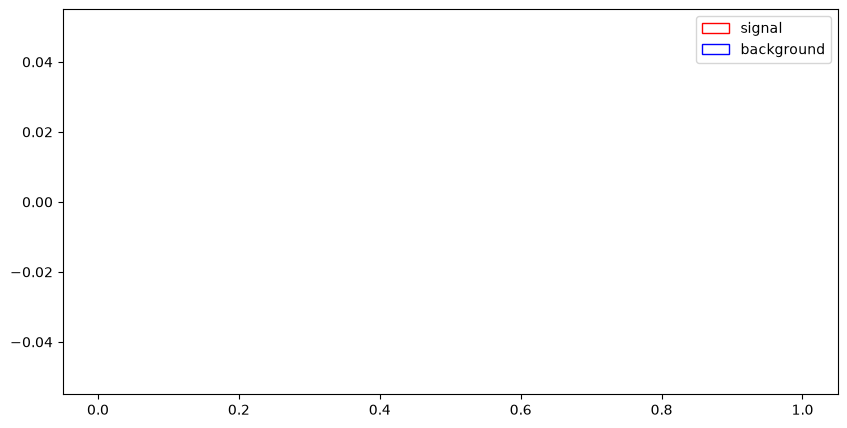

l_1_eta


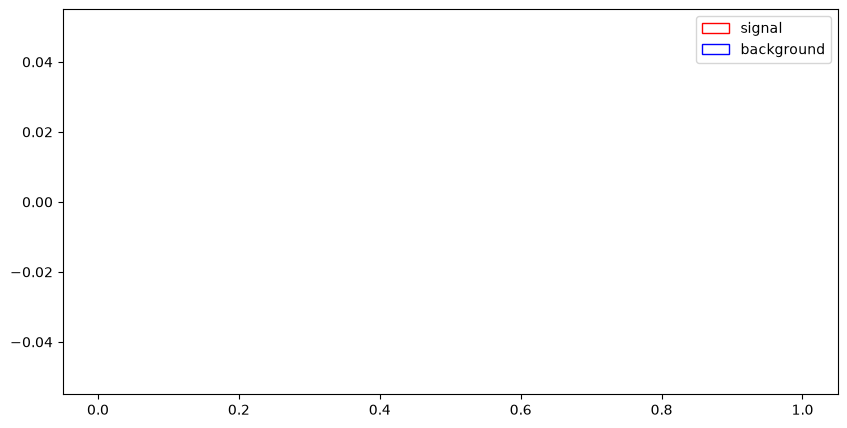

l_1_phi


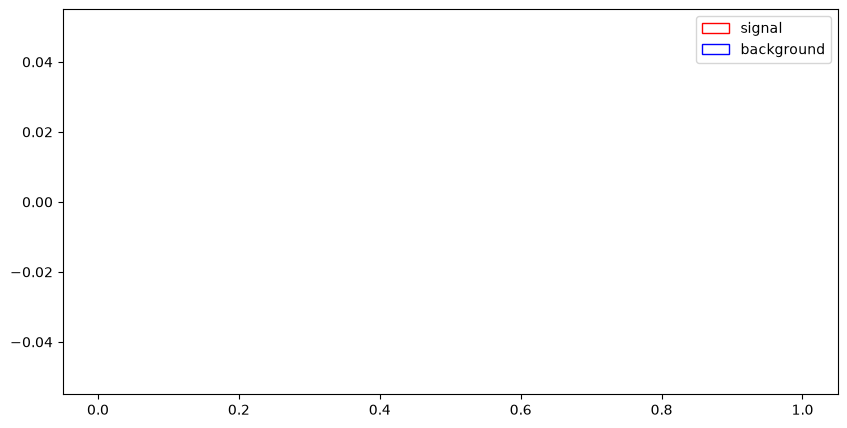

l_2_pT


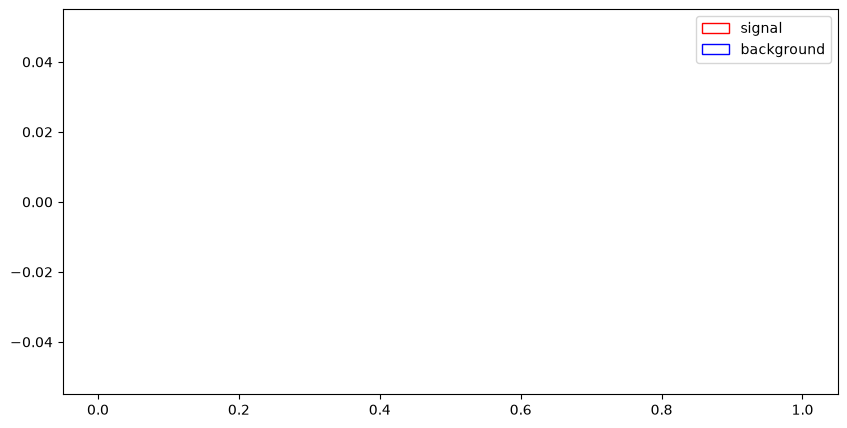

l_2_eta


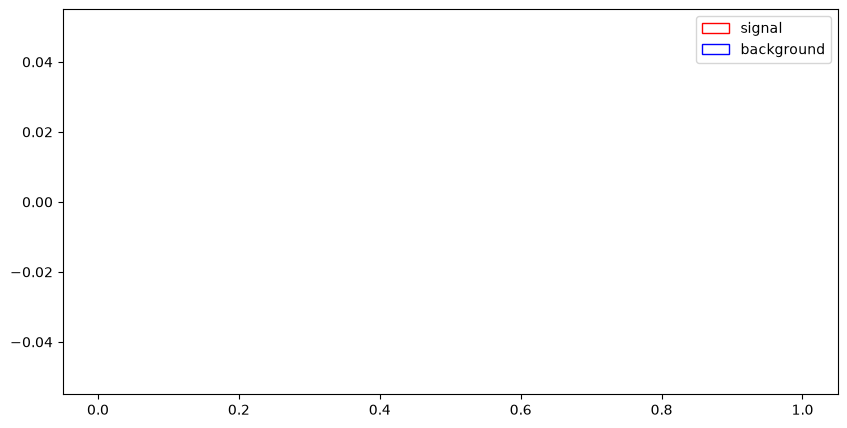

l_2_phi


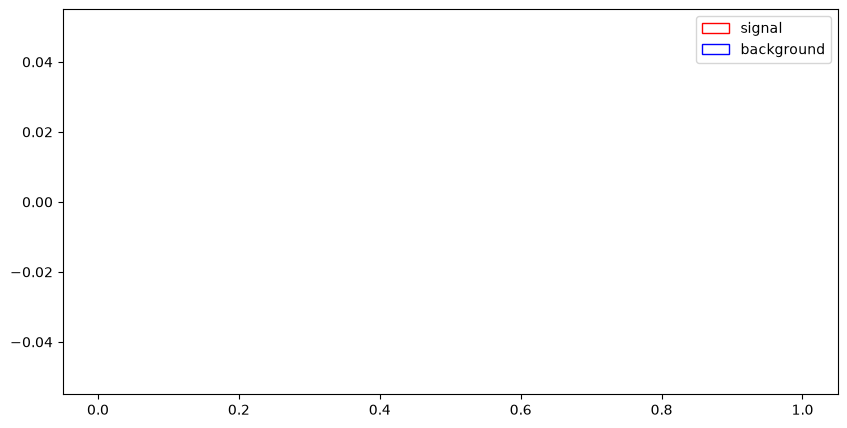

MET


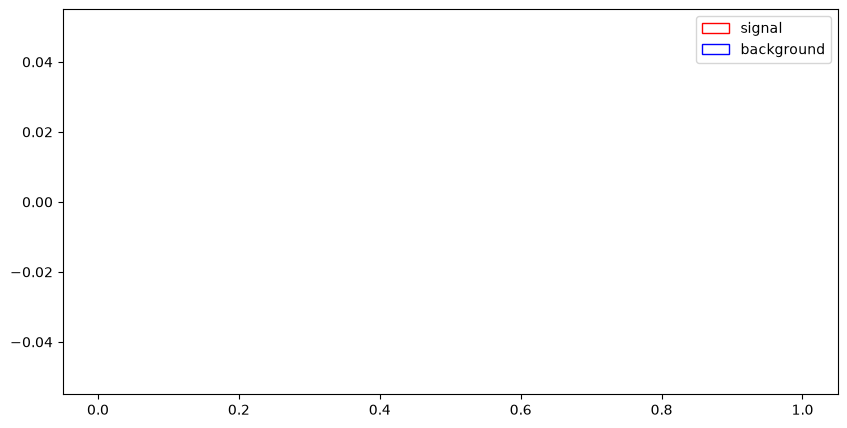

MET_phi


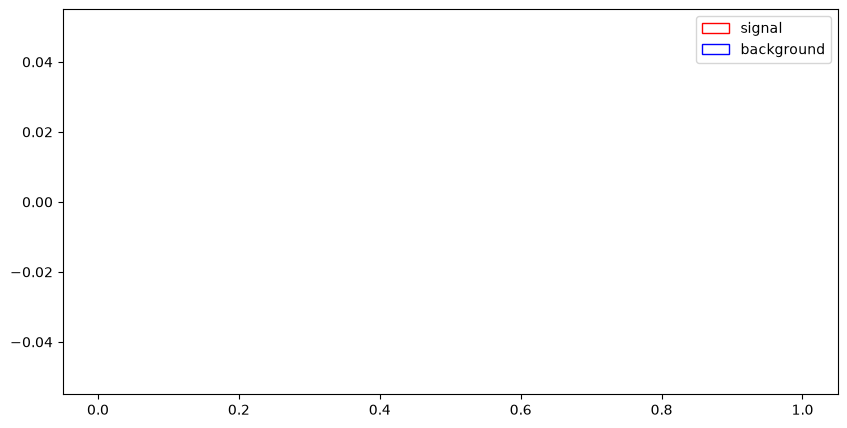

MET_rel


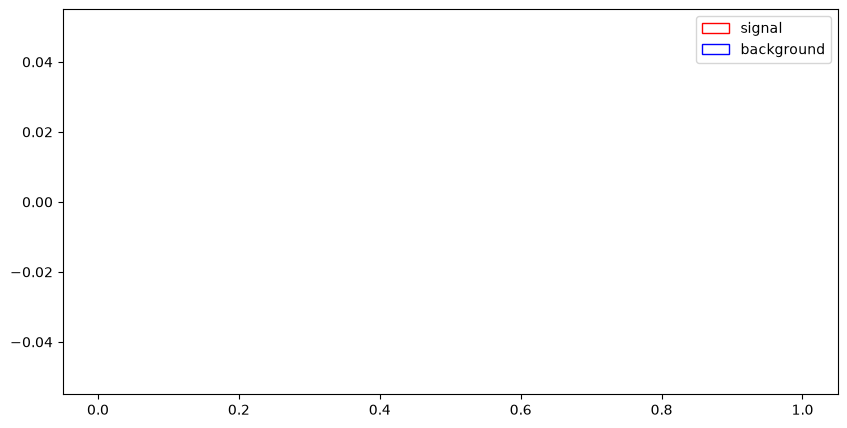

axial_MET


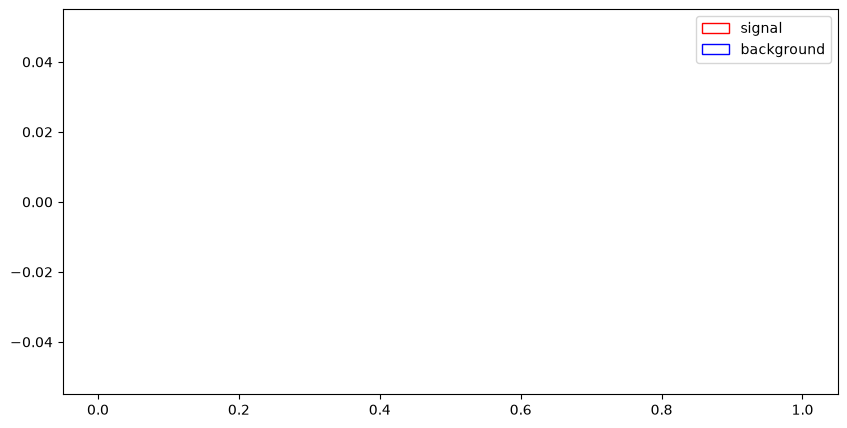

M_R


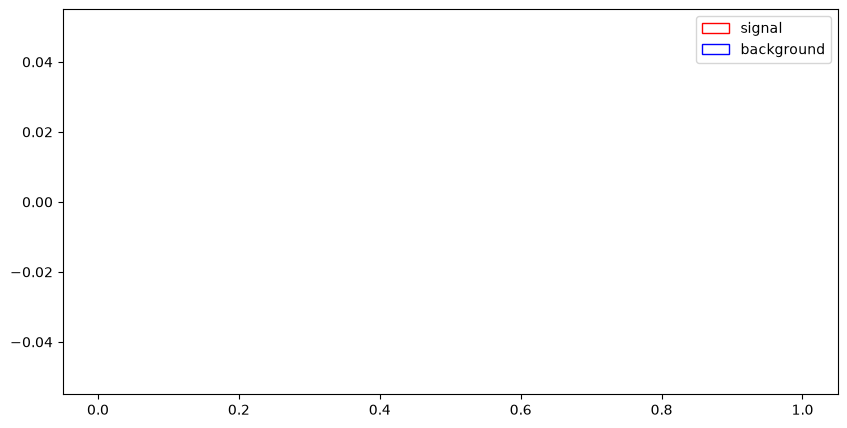

M_TR_2


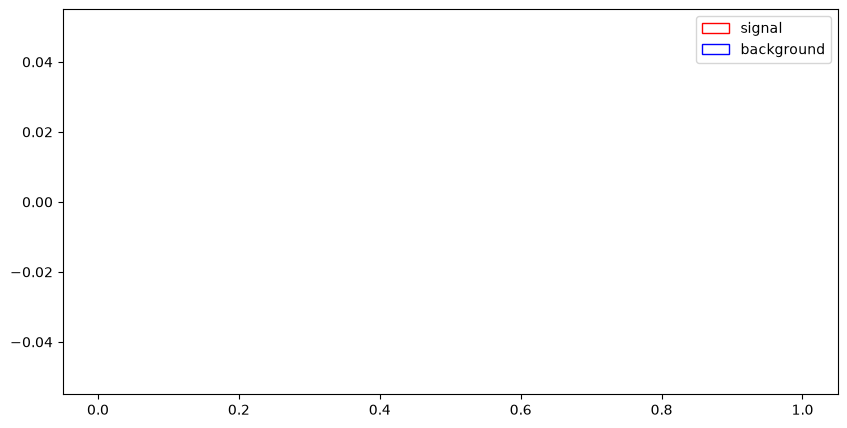

R


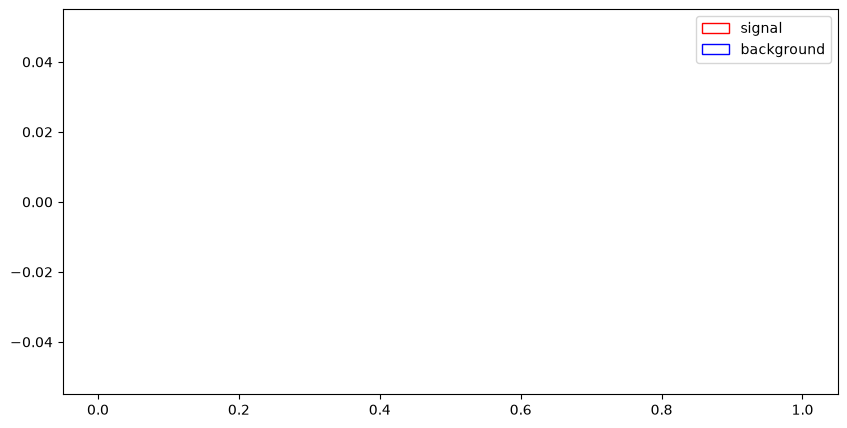

MT2


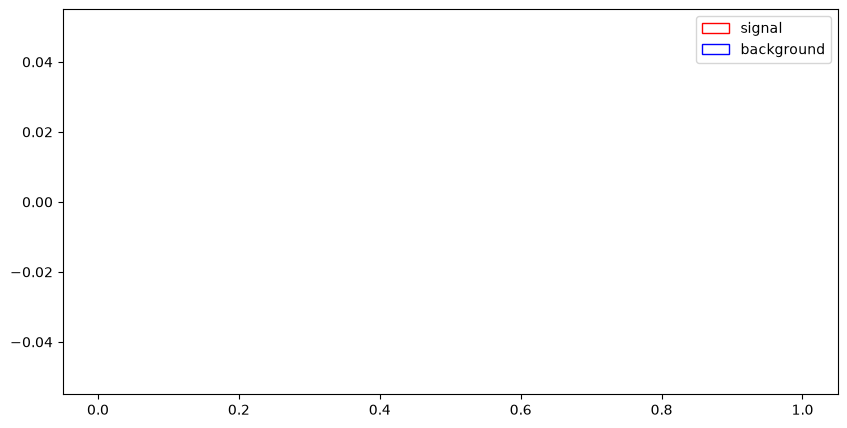

S_R


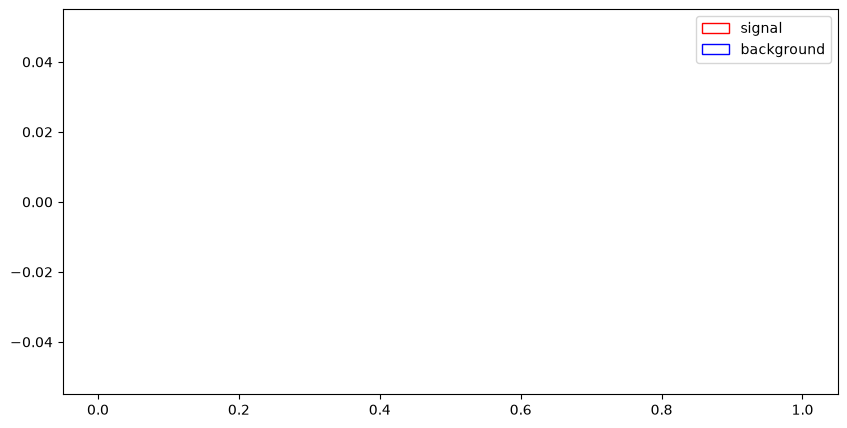

M_Delta_R


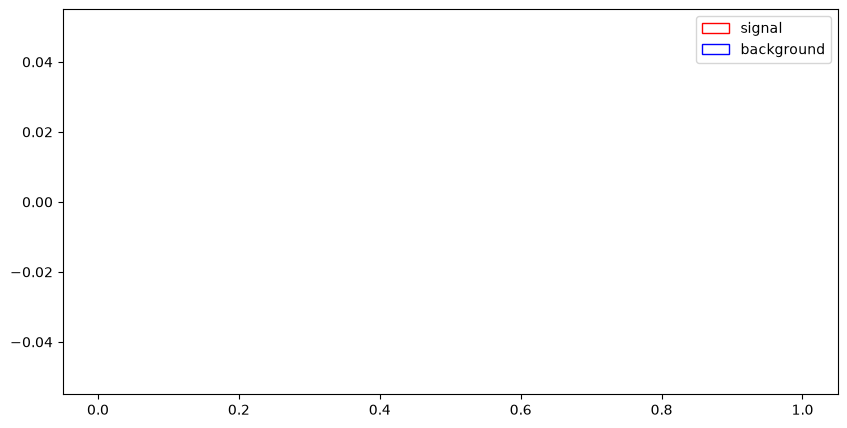

dPhi_r_b


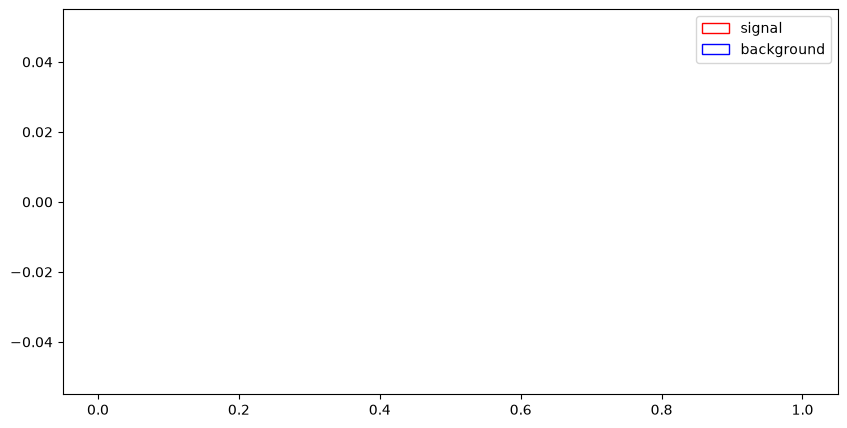

cos_theta_r1


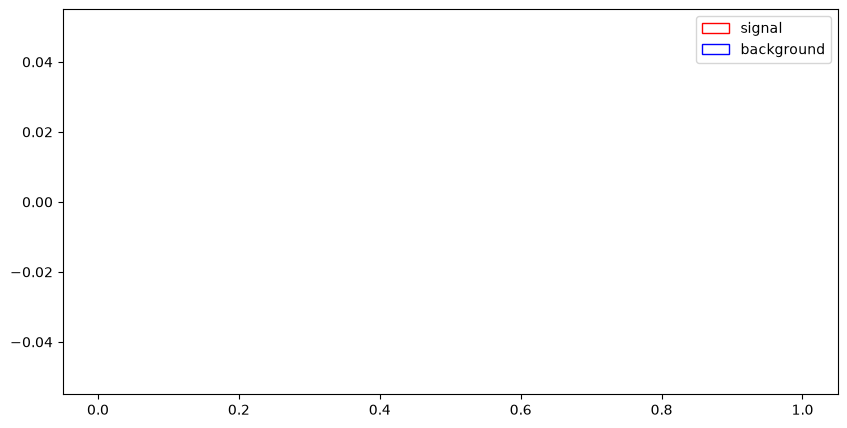

In [18]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

I used the smaller SUSY dataset to make plotting faster. The plots compare the low-level and high-level variables. Density=True allows comparison between groups of different sizes.

Using Matplotlib I compared signal and background distributions for the eight low level and ten high level features. I then made a histogram with two figures in order to better compare the variables. And I also used a normalized histogram because of the difference in the number of events between signal and background.

A limitation is that I used a smaller sample of only 120,000 observations instead of the full dataset.


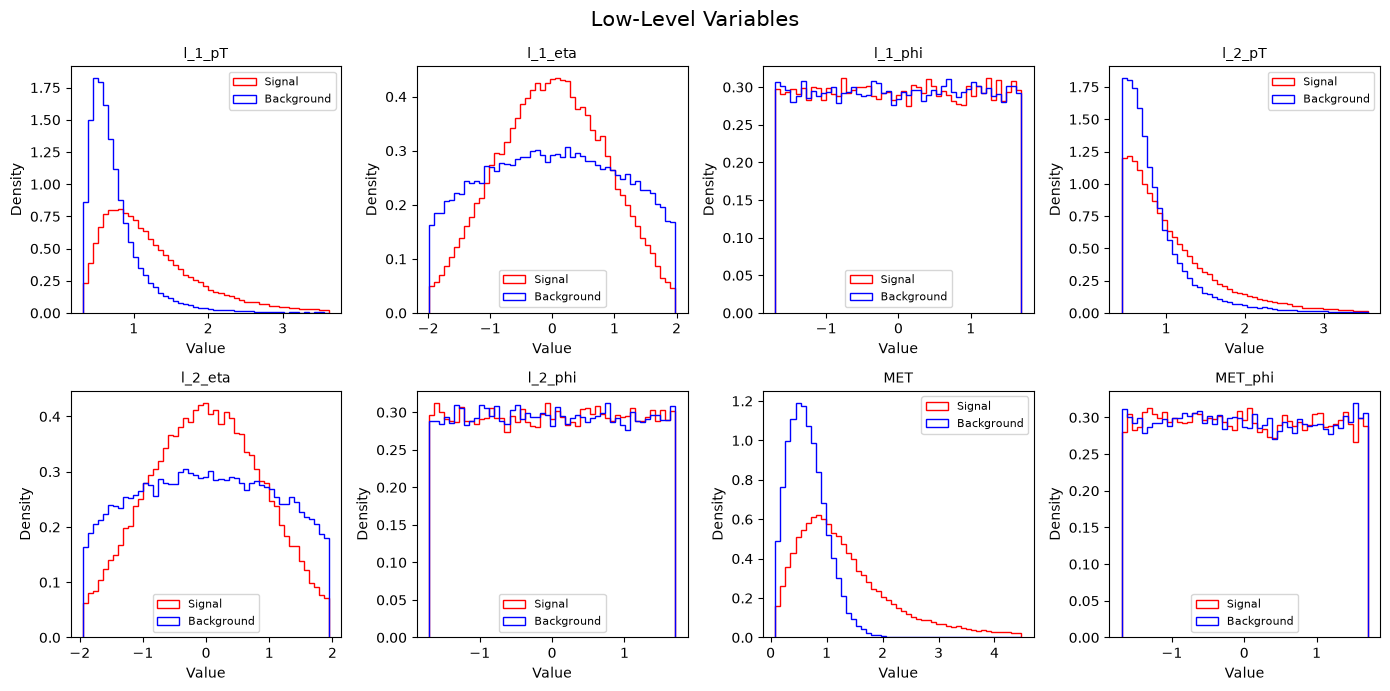

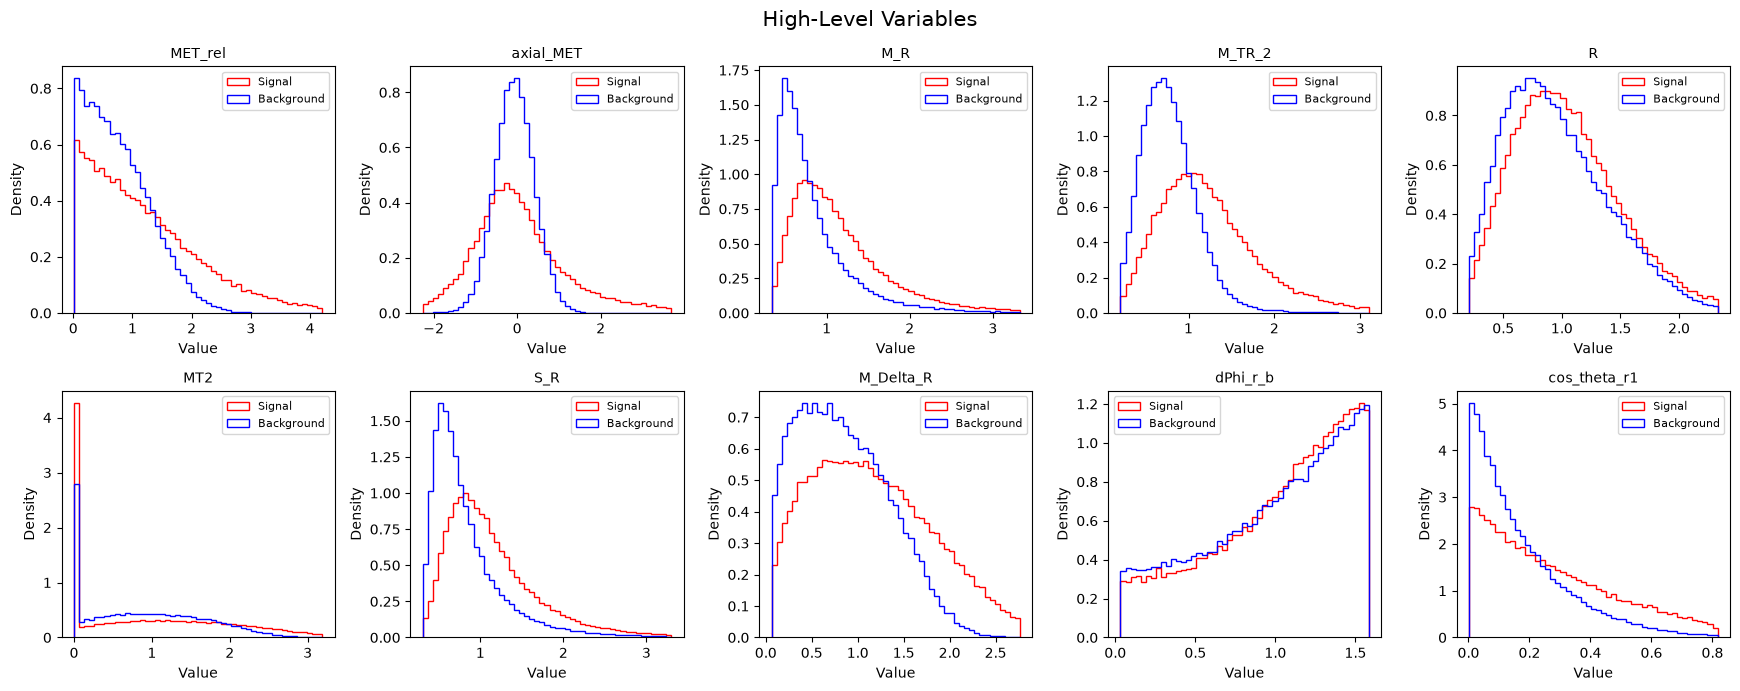

In [1]:

# EX3

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

VarNames = [
    "signal", "l_1_pT", "l_1_eta", "l_1_phi",
    "l_2_pT", "l_2_eta", "l_2_phi",
    "MET", "MET_phi", "MET_rel", "axial_MET",
    "M_R", "M_TR_2", "R", "MT2",
    "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"
]

RawNames = VarNames[1:9]
FeatureNames = VarNames[9:]

df = pd.read_csv("SUSY-small.csv", header=None, names=VarNames)

df_sig = df[df["signal"] == 1]
df_bkg = df[df["signal"] == 0]

# Function to display a group of variables in one figure.
def plot_variables(variables, title, columns):

    rows = 2
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(3.5 * columns, 7)
    )

    for ax, var in zip(axes.flat, variables):

        # Use the same bin edges for signal and background.
        lower, upper = df[var].quantile([0.01, 0.99])
        bins = np.linspace(lower, upper, 50)

        ax.hist(df_sig[var], bins=bins,
                density=True, histtype="step",
                color="red", label="Signal")

        ax.hist(df_bkg[var], bins=bins,
                density=True, histtype="step",
                color="blue", label="Background")

        ax.set_title(var, fontsize=10)
        ax.set_xlabel("Value")
        ax.set_ylabel("Density")
        ax.legend(fontsize=8)

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


# Figure 5: Eight low-level variables
plot_variables(RawNames, "Low-Level Variables", 4)

# Figure 6: Ten high-level variables
plot_variables(FeatureNames, "High-Level Variables", 5)




## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [ ]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

In the code below for exercise 4.2, I used numpy to compare relationships betwen the variable of the SUSY dataset and created a function which will help me from now on to repeat the analysis for different groups of features.

NUmpy was used to calculate the covariance and correlation matrices for all eighteen variables. Covariance shows the change between a pair of variables. Correlation matrices allow you to quickly ascertain from a value between -1 and 1 how strong the relationship is and if it is negatively or positively/ strong or weakly correlated.

In [2]:
import numpy as np
import pandas as pd
import tabulate
from IPython.display import HTML, display

def compare_variables(data, columns, title):

    # Select the variables and remove missing values.
    values = data[columns].dropna().to_numpy()

    # Calculate covariance and correlation matrices.
    covariance = np.cov(values, rowvar=False)
    correlation = np.corrcoef(values, rowvar=False)

    # Add variable names to the tables.
    cov_table = pd.DataFrame(
        covariance, index=columns, columns=columns
    )

    corr_table = pd.DataFrame(
        correlation, index=columns, columns=columns
    )

    print(title, "- Covariance Matrix")
    display(HTML(tabulate.tabulate(
        cov_table.round(3),
        headers="keys",
        tablefmt="html"
    )))

    print(title, "- Correlation Matrix")
    display(HTML(tabulate.tabulate(
        corr_table.round(3),
        headers="keys",
        tablefmt="html"
    )))


# Compare all variables and the two feature groups.
compare_variables(df, VarNames[1:], "All Variables")
compare_variables(df, RawNames, "Low-Level Variables")
compare_variables(df, FeatureNames, "High-Level Variables")


All Variables - Covariance Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.465,-0.001,-0.002,0.301,0,0.004,0.231,-0.002,0.103,-0.014,0.361,0.289,-0.058,-0.011,0.34,0.1,-0.046,0.023
l_1_eta,-0.001,1.006,-0.003,-0.001,0.409,-0.001,-0.004,-0.001,-0.003,-0.005,-0.002,-0.001,-0,0.001,-0.002,-0.001,-0.002,0
l_1_phi,-0.002,-0.003,1.007,0.001,-0,-0.267,0,-0.185,-0.001,0.001,-0,-0,-0,0.001,0,0.001,0.003,-0
l_2_pT,0.301,-0.001,0.001,0.42,0,0.001,0.08,-0.003,0.003,0.052,0.321,0.162,-0.099,-0.067,0.317,0.008,-0.004,-0.028
l_2_eta,0,0.409,-0,0,1.01,-0.005,-0,-0.001,0.001,-0.003,0.001,0,-0.001,0.003,0.001,0.001,-0,-0
l_2_phi,0.004,-0.001,-0.267,0.001,-0.005,1.003,0.001,-0.036,0.001,-0.003,0.002,0.002,0,0.003,0.002,0.001,-0.002,0.001
MET,0.231,-0.004,0,0.08,-0,0.001,0.767,-0.001,0.55,0.146,0.146,0.369,0.188,0.158,0.168,0.316,0.146,0.074
MET_phi,-0.002,-0.001,-0.185,-0.003,-0.001,-0.036,-0.001,1.006,-0.003,-0.002,-0.004,-0.001,0.002,0.002,-0.004,0.001,-0.001,0.001
MET_rel,0.103,-0.003,-0.001,0.003,0.001,0.001,0.55,-0.003,0.787,-0.124,0.047,0.305,0.248,0.41,0.086,0.414,0.147,0.056
axial_MET,-0.014,-0.005,0.001,0.052,-0.003,-0.003,0.146,-0.002,-0.124,1.008,0.015,-0.192,-0.183,-0.462,-0.045,-0.236,-0.026,-0.055


All Variables - Correlation Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,-0.003,0.681,0,0.006,0.387,-0.003,0.17,-0.02,0.851,0.724,-0.182,-0.019,0.812,0.235,-0.156,0.168
l_1_eta,-0.001,1,-0.003,-0.002,0.406,-0.001,-0.005,-0.001,-0.003,-0.005,-0.003,-0.001,-0.001,0.001,-0.003,-0.001,-0.005,0.001
l_1_phi,-0.003,-0.003,1,0.001,-0,-0.265,0,-0.184,-0.001,0.001,-0,-0.001,-0.001,0.002,0,0.001,0.006,-0.001
l_2_pT,0.681,-0.002,0.001,1,0,0.001,0.142,-0.004,0.005,0.08,0.796,0.427,-0.323,-0.12,0.797,0.019,-0.012,-0.218
l_2_eta,0,0.406,-0,0,1,-0.005,-0,-0.001,0.001,-0.003,0.002,0.001,-0.002,0.003,0.002,0.002,-0,-0
l_2_phi,0.006,-0.001,-0.265,0.001,-0.005,1,0.001,-0.036,0.001,-0.003,0.004,0.003,0.001,0.003,0.003,0.002,-0.005,0.005
MET,0.387,-0.005,0,0.142,-0,0.001,1,-0.001,0.708,0.166,0.268,0.721,0.457,0.21,0.311,0.579,0.381,0.425
MET_phi,-0.003,-0.001,-0.184,-0.004,-0.001,-0.036,-0.001,1,-0.004,-0.002,-0.006,-0.001,0.004,0.003,-0.006,0.001,-0.003,0.003
MET_rel,0.17,-0.003,-0.001,0.005,0.001,0.001,0.708,-0.004,1,-0.139,0.086,0.589,0.594,0.538,0.157,0.748,0.379,0.319
axial_MET,-0.02,-0.005,0.001,0.08,-0.003,-0.003,0.166,-0.002,-0.139,1,0.023,-0.327,-0.388,-0.535,-0.073,-0.378,-0.06,-0.276


Low-Level Variables - Covariance Matrix


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.465,-0.001,-0.002,0.301,0,0.004,0.231,-0.002
l_1_eta,-0.001,1.006,-0.003,-0.001,0.409,-0.001,-0.004,-0.001
l_1_phi,-0.002,-0.003,1.007,0.001,-0,-0.267,0,-0.185
l_2_pT,0.301,-0.001,0.001,0.42,0,0.001,0.08,-0.003
l_2_eta,0,0.409,-0,0,1.01,-0.005,-0,-0.001
l_2_phi,0.004,-0.001,-0.267,0.001,-0.005,1.003,0.001,-0.036
MET,0.231,-0.004,0,0.08,-0,0.001,0.767,-0.001
MET_phi,-0.002,-0.001,-0.185,-0.003,-0.001,-0.036,-0.001,1.006


... (2 outputs left out)

High-Level Variables - Covariance Matrix


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.787,-0.124,0.047,0.305,0.248,0.41,0.086,0.414,0.147,0.056
axial_MET,-0.124,1.008,0.015,-0.192,-0.183,-0.462,-0.045,-0.236,-0.026,-0.055
M_R,0.047,0.015,0.388,0.21,-0.112,-0.035,0.376,0.076,-0.028,-0.014
M_TR_2,0.305,-0.192,0.21,0.341,0.105,0.191,0.229,0.244,0.059,0.052
R,0.248,-0.183,-0.112,0.105,0.222,0.232,-0.082,0.165,0.087,0.058
MT2,0.41,-0.462,-0.035,0.191,0.232,0.738,-0.009,0.434,0.022,0.045
S_R,0.086,-0.045,0.376,0.229,-0.082,-0.009,0.378,0.098,-0.003,-0.01
M_Delta_R,0.414,-0.236,0.076,0.244,0.165,0.434,0.098,0.389,0.042,0.039
dPhi_r_b,0.147,-0.026,-0.028,0.059,0.087,0.022,-0.003,0.042,0.19,0.009
cos_theta_r1,0.056,-0.055,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


High-Level Variables - Correlation Matrix


,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.139,0.086,0.589,0.594,0.538,0.157,0.748,0.379,0.319
axial_MET,-0.139,1,0.023,-0.327,-0.388,-0.535,-0.073,-0.378,-0.06,-0.276
M_R,0.086,0.023,1,0.578,-0.381,-0.065,0.981,0.195,-0.104,-0.114
M_TR_2,0.589,-0.327,0.578,1,0.382,0.381,0.637,0.669,0.23,0.452
R,0.594,-0.388,-0.381,0.382,1,0.574,-0.283,0.562,0.422,0.628
MT2,0.538,-0.535,-0.065,0.381,0.574,1,-0.017,0.81,0.058,0.264
S_R,0.157,-0.073,0.981,0.637,-0.283,-0.017,1,0.255,-0.01,-0.082
M_Delta_R,0.748,-0.378,0.195,0.669,0.562,0.81,0.255,1,0.155,0.319
dPhi_r_b,0.379,-0.06,-0.104,0.23,0.422,0.058,-0.01,0.155,1,0.105
cos_theta_r1,0.319,-0.276,-0.114,0.452,0.628,0.264,-0.082,0.319,0.105,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 